# Predictive learning: inspect the conditional quantity being learned

Means, class probabilities, counts, and quantiles answer different questions. This notebook uses generated data to compare each model's predictions with both held-out observations and the generating conditional function.

Preprocessing is fitted inside the training pipeline. Test rows stay outside fitting, including in the neural example. The models use the same Convexity fitted-predictor interface, but their uncertainty claims remain different. [Learning catalog](../docs/predictive_learning.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import expit
from convexity.math import learning as learn, transforms as tx

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.figsize": (10, 3.8), "axes.grid": True,
                     "grid.alpha": .18, "figure.dpi": 110})

## Regularization changes coefficients before it changes predictive error

An orthogonal design makes the elastic-net effect easy to read: small coefficients can become zero and large ones shrink. The second experiment uses differently scaled features and a training-only standardizer.

Compare held-out MSE across models. Shrinkage is not guaranteed to improve this low-dimensional, correctly specified example. Its usefulness depends on noise, sample size, and the stability of the design.

In [2]:
orthogonal = np.vstack([np.eye(3), -np.eye(3)]) * np.sqrt(3)
beta = np.array([2.0, -0.1, -3.0])
alpha, ratio = (0.5, 0.4)
model = learn.ElasticNet(alpha=alpha, l1_ratio=ratio).fit(orthogonal, 7 + orthogonal @ beta)
expected = np.sign(beta) * np.maximum(np.abs(beta) - alpha * ratio, 0) / (1 + alpha * (1 - ratio))
pd.DataFrame({'unpenalized': beta, 'elastic net': model.coefficients, 'analytic': expected})

,unpenalized,elastic net,analytic
0,2.0,1.384615,1.384615
1,-0.1,-0.000000,-0.000000
2,-3.0,-2.153846,-2.153846


In [3]:
X = rng.normal(size=(1200, 3))*[1., 3., .5]
beta = np.array([1.5, -2., .5])
y = 3 + X @ beta + .3*rng.normal(size=len(X))
training, test = X[:900], X[900:]
specifications = {"OLS": learn.LinearRegression(), "Ridge": learn.Ridge(alpha=.01),
                  "Lasso": learn.Lasso(alpha=.02), "Elastic net": learn.ElasticNet(alpha=.02)}
models = {label: learn.Pipeline((tx.Standardize(),), tool).fit(training, y[:900])
          for label, tool in specifications.items()}
pd.DataFrame({label: {"training MSE": np.mean((model.predict(training)-y[:900])**2),
                     "test MSE": np.mean((model.predict(test)-y[900:])**2),
                     "test error against conditional mean": np.mean((model.predict(test)-(3+test@beta))**2)}
              for label, model in models.items()}).T

,training MSE,test MSE,test error against conditional mean
OLS,0.087539,0.096317,0.000313
Ridge,0.091249,0.098565,0.003917
Lasso,0.088835,0.096558,0.001119
Elastic net,0.093189,0.100152,0.005783


## Counts need an exposure as well as a rate

The Poisson mean is `exposure * exp(linear predictor)`. A log-exposure offset has a fixed coefficient of one; it is not an extra coefficient to estimate. Both training and prediction must supply it.

Inspect held-out predicted counts against the generating means and observed counts. The observed count remains random even if its mean is perfectly estimated. A Poisson mean model by itself does not establish that real data have Poisson variance.

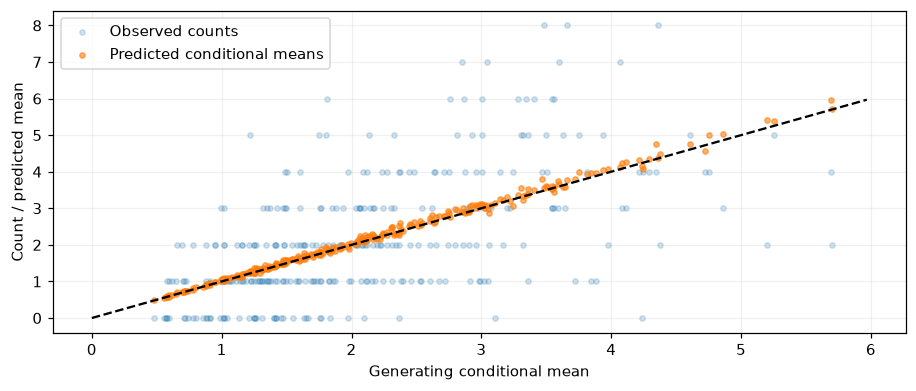

,generating coefficient,estimated coefficient
0,0.20,0.203929
1,-0.08,-0.076769
2,0.10,0.155499


In [4]:
exposure = rng.uniform(.5, 2., len(X))
true_mean = np.exp(.5+X@[.2, -.08, .1])*exposure
counts = rng.poisson(true_mean)
poisson = learn.GeneralizedLinearModel("poisson").fit(training, counts[:900], offset=np.log(exposure[:900]))
predicted = poisson.predict(test, offset=np.log(exposure[900:]))
fig, ax = plt.subplots()
ax.scatter(true_mean[900:], counts[900:], alpha=.2, s=12, label="Observed counts")
ax.scatter(true_mean[900:], predicted, alpha=.6, s=12, label="Predicted conditional means")
extent = [0, max(true_mean[900:].max(), predicted.max())]
ax.plot(extent, extent, "k--")
ax.set(xlabel="Generating conditional mean", ylabel="Count / predicted mean")
ax.legend()
plt.show()
pd.DataFrame({"generating coefficient": [.2, -.08, .1], "estimated coefficient": poisson.coefficients})

## Class probabilities and binomial proportions

Logistic regression learns the probability of a labelled outcome; its probability columns follow `classes`. A binomial GLM uses successes and trial counts, so a row with twenty trials contains more information than a single binary label.

Both models below are fitted only on training rows. Comparing with known generating probabilities separates probability estimation from the noise of a realized class label. Good classification accuracy alone would not establish calibrated probabilities.

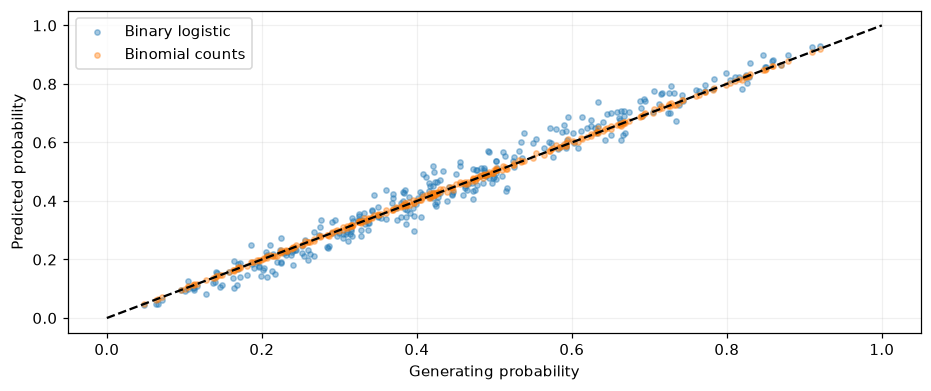

In [5]:
true_probability = expit(-.3+X@[.8, -.2, .4])
trials = rng.integers(10, 30, len(X))
successes = rng.binomial(trials, true_probability)
binomial = learn.GeneralizedLinearModel("binomial").fit(training, successes[:900], trials=trials[:900])
labels = np.where(rng.random(len(X)) < true_probability, "success", "failure")
logistic = learn.LogisticRegression().fit(training, labels[:900])
success_column = list(logistic.classes).index("success")
probability = logistic.predict_proba(test)[:, success_column]
binomial_probability = binomial.predict_proba(test)[:, 1]
fig, ax = plt.subplots()
ax.scatter(true_probability[900:], probability, s=12, alpha=.4, label="Binary logistic")
ax.scatter(true_probability[900:], binomial_probability, s=12, alpha=.4, label="Binomial counts")
ax.plot([0, 1], [0, 1], "k--")
ax.set(xlabel="Generating probability", ylabel="Predicted probability")
ax.legend()
plt.show()

## Quantiles describe changing spread

We generate uniform noise with a scale that changes with the input. Conditional quantile curves are therefore known. `QuantileRegression` fits the requested levels directly; it does not add a Gaussian distribution to a mean predictor.

Inspect curve shape and held-out coverage together. Pooled coverage can look correct while predictions fail in part of the feature space. Independently fitted quantiles can also cross; the API does not sort their values to hide that problem.

In [6]:
qx = rng.uniform(-1, 1, (2000, 1))
scale = 1 + 0.4 * qx[:, 0]
qy = 2 + 3 * qx[:, 0] + scale * rng.uniform(-1, 1, len(qx))
levels = np.array([0.1, 0.5, 0.9])
quantile = learn.QuantileRegression(tuple(levels)).fit(qx[:1500], qy[:1500])
grid = np.linspace(-1, 1, 100)[:, None]
truth = 2 + 3 * grid + (1 + 0.4 * grid) * (2 * levels - 1)
estimated = quantile.predict_quantiles(grid)
coverage = np.mean(qy[1500:, None] <= quantile.predict_quantiles(qx[1500:]), axis=0)
pd.DataFrame({'quantile': levels, 'held-out coverage': coverage})

,quantile,held-out coverage
0,0.1,0.094
1,0.5,0.494
2,0.9,0.914


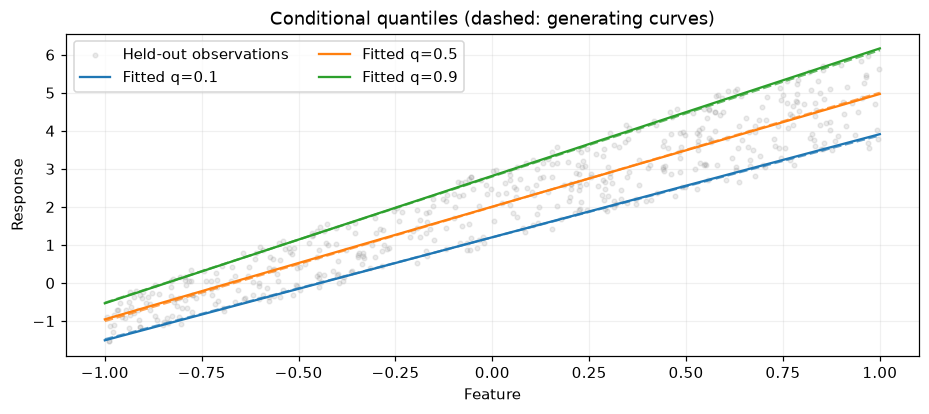

In [7]:
fig, ax = plt.subplots()
ax.scatter(qx[1500:, 0], qy[1500:], s=9, alpha=0.15, color='gray', label='Held-out observations')
for j, level in enumerate(levels):
    line, = ax.plot(grid[:, 0], estimated[:, j], label=f'Fitted q={level:.1f}')
    ax.plot(grid[:, 0], truth[:, j], color=line.get_color(), linestyle='--', alpha=0.7)
ax.set(xlabel='Feature', ylabel='Response', title='Conditional quantiles (dashed: generating curves)')
ax.legend(ncol=2)
plt.show()

In [8]:
quantiles_test = quantile.predict_quantiles(qx[1500:])
groups = np.where(qx[1500:, 0] < 0, "negative input", "nonnegative input")
pd.DataFrame([{ "input group": group, "nominal quantile": level,
               "observed fraction below": np.mean(qy[1500:][groups==group] <= quantiles_test[groups==group, j])}
              for group in np.unique(groups) for j, level in enumerate(levels)])

,input group,nominal quantile,observed fraction below
0,negative input,0.1,0.089744
1,negative input,0.5,0.508547
2,negative input,0.9,0.901709
3,nonnegative input,0.1,0.097744
4,nonnegative input,0.5,0.481203
5,nonnegative input,0.9,0.924812


## Nonlinear models can interpolate well and extrapolate poorly

The response is a quadratic in one feature plus a jump in another. A tree, forest, and boosting model see only the training rows. Their piecewise predictions approximate the discontinuity differently.

Compare the held-out errors, then the two response slices. Extending a slice outside the training domain reveals a limitation that an IID test split inside the domain would not expose.

In [9]:
tree_x = rng.uniform(-2, 2, (900, 2))
tree_y = tree_x[:, 0] ** 2 + (tree_x[:, 1] > 0)
tools = [learn.DecisionTree(max_depth=6), learn.RandomForest(n_estimators=40), learn.ExtraTrees(n_estimators=40), learn.GradientBoosting(n_estimators=100)]
tree_models = {type(tool).__name__: tool.fit(tree_x[:700], tree_y[:700]) for tool in tools}
mse = {name: np.mean((model.predict(tree_x[700:]) - tree_y[700:]) ** 2) for name, model in tree_models.items()}
pd.Series(mse, name='held-out MSE').to_frame()

,held-out MSE
DecisionTree,0.024609
RandomForest,0.006459
ExtraTrees,0.006927
GradientBoosting,0.003443


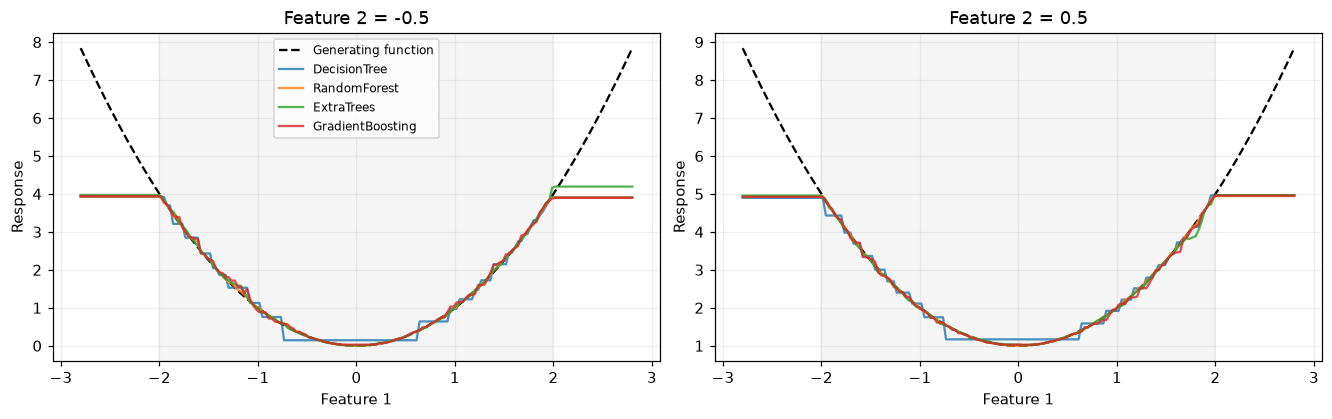

In [10]:
slice_x = np.linspace(-2.8, 2.8, 180)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), layout="constrained")
for ax, second_coordinate in zip(axes, [-.5, .5]):
    features = np.column_stack((slice_x, np.full_like(slice_x, second_coordinate)))
    ax.plot(slice_x, slice_x**2+(second_coordinate>0), "k--", label="Generating function")
    for label, model in tree_models.items():
        ax.plot(slice_x, model.predict(features), label=label, alpha=.8)
    ax.axvspan(-2, 2, color="gray", alpha=.08)
    ax.set(xlabel="Feature 1", ylabel="Response", title=f"Feature 2 = {second_coordinate}")
axes[0].legend(fontsize=8)
plt.show()

## A neural fit needs inspection away from its training points

Fit a small neural regressor on a noisy sine curve at forty input locations. Dense query points reveal interpolation, while the shaded interval marks the training domain. The loss history describes optimization on training data; it is not a generalization score or a posterior uncertainty band.

The clean sine curve lets us inspect approximation error independently of observation noise. PyTorch is required for this section.

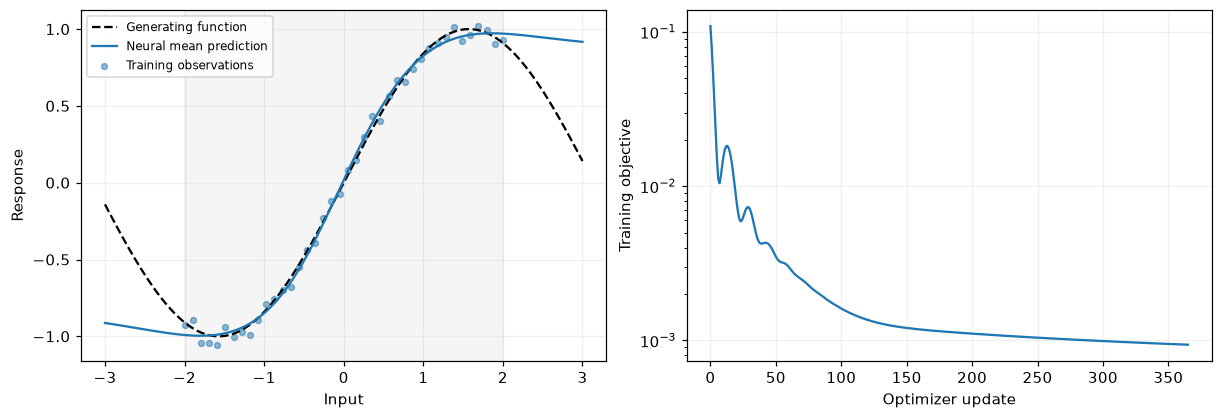

,region,RMSE against sine
0,inside training domain,0.028145
1,outside training domain,0.436774


In [11]:
import torch
torch.set_num_threads(1)
neural_x = np.linspace(-2, 2, 40)[:, None]
neural_y = np.sin(neural_x[:, 0]) + rng.normal(0, .04, len(neural_x))
network = learn.NeuralRegressor(hidden_layers=(12,), seed=7, maxiter=3000, tolerance=3e-4).fit(neural_x, neural_y)
neural_query = np.linspace(-3, 3, 240)[:, None]
neural_prediction = network.predict(neural_query)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
axes[0].plot(neural_query[:, 0], np.sin(neural_query[:, 0]), "k--", label="Generating function")
axes[0].plot(neural_query[:, 0], neural_prediction, label="Neural mean prediction")
axes[0].scatter(neural_x[:, 0], neural_y, s=15, alpha=.5, label="Training observations")
axes[0].axvspan(-2, 2, color="gray", alpha=.08)
axes[0].set(xlabel="Input", ylabel="Response")
axes[0].legend(fontsize=8)
axes[1].semilogy(network.loss_history)
axes[1].set(xlabel="Optimizer update", ylabel="Training objective")
plt.show()
pd.DataFrame({"region": ["inside training domain", "outside training domain"],
    "RMSE against sine": [np.sqrt(np.mean((neural_prediction[mask]-np.sin(neural_query[mask, 0]))**2))
                          for mask in [np.abs(neural_query[:, 0])<=2, np.abs(neural_query[:, 0])>2]]})

Try shrinking the training sample or increasing the noise before increasing model complexity. For each experiment, keep the prediction target clear: a mean error, a probability calibration error, and a quantile coverage error are not interchangeable metrics.